# Appendix B.3: where the adapter sits (Figure 4)

**Inputs** (GPU, run once; `results/<experiment>/`):
- `python -m factdepth.run experiments/configs/main.yaml`
- `python -m factdepth.run experiments/configs/fig1.yaml`
- `python -m factdepth.run experiments/configs/mlp_out.yaml`
- `python -m factdepth.run experiments/configs/mlp_hidden.yaml`

The outputs below were computed from the paper's own result files; rerunning the configs gives the same numbers.

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "factdepth").exists())
sys.path.insert(0, str(ROOT / "src"))
from factdepth import config as C
from factdepth.analysis import numbers, plots, tables
# the results of the configs (results/<experiment>/, or the folder in FACTDEPTH_RESULTS)
print({k: C.results(k).exists() for k in ['main', 'fig1', 'mlp_out', 'mlp_hidden']})

{'main': True, 'fig1': True, 'mlp_out': True, 'mlp_hidden': True}


qv       (d) step   0: unseen 0% other 0% lost 0.0 drop +0.0 layer None
qv       (d) step  16: unseen 2% other 0% lost 2.5 drop -0.5 layer 47
qv       (d) step  32: unseen 20% other 0% lost 3.2 drop -1.9 layer 42.0
qv       (d) step  40: unseen 41% other 2% lost 3.6 drop -3.5 layer 40.0
qv       (d) step  48: unseen 56% other 3% lost 4.3 drop -3.3 layer 40
qv       (d) step  56: unseen 64% other 4% lost 5.2 drop -2.1 layer 40.0
qv       (d) step  64: unseen 67% other 4% lost 6.3 drop -0.7 layer 39.0
qv       (d) step  96: unseen 70% other 5% lost 7.2 drop +0.6 layer 39.0
qv       (d) step 128: unseen 70% other 6% lost 7.3 drop +0.7 layer 39.0
qv       (d) step 256: unseen 71% other 6% lost 7.5 drop +0.9 layer 38
qv       (e) S1  : unseen 48% other 2% lost 4.4 drop -0.7 layer 41.0
qv       (e) S3  : unseen 66% other 3% lost 5.6 drop -1.4 layer 40.0
qv       (e) S5  : unseen 67% other 4% lost 6.3 drop -0.7 layer 39.0
qv       (e) S10 : unseen 69% other 5% lost 6.8 drop -0.4 layer 39.0
qv

mlp_out  (d) step   0: unseen 0% other 0% lost 0.0 drop +0.0 layer None
mlp_out  (d) step  32: unseen 89% other 23% lost 10.5 drop +3.8 layer 38
mlp_out  (d) step  64: unseen 98% other 36% lost 15.5 drop +9.4 layer 35.0
mlp_out  (d) step 128: unseen 98% other 37% lost 15.6 drop +9.5 layer 35
mlp_out  (d) step 256: unseen 98% other 37% lost 15.9 drop +9.8 layer 35
mlp_out  (e) S1  : unseen 89% other 21% lost 10.4 drop +4.2 layer 38.0
mlp_out  (e) S5  : unseen 98% other 36% lost 15.5 drop +9.4 layer 35.0
mlp_out  (e) Sall: unseen 100% other 59% lost 21.8 drop +16.4 layer 32.0


saved figures/fig4_lora_site.pdf


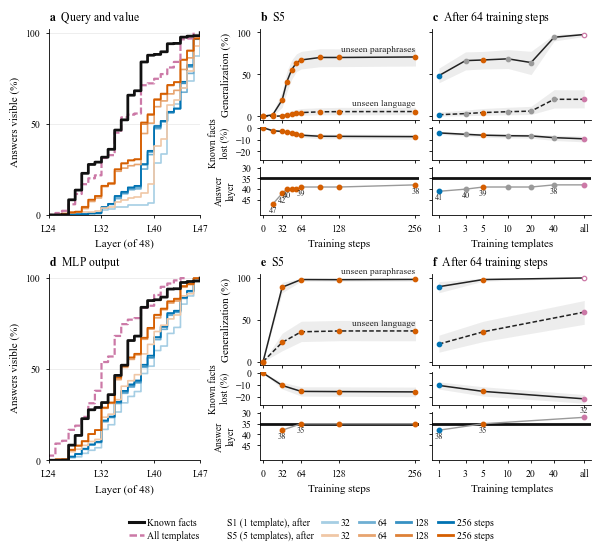

In [2]:
fig = plots.fig4()
print("saved", plots.save(fig, "fig4_lora_site"))

In [3]:
print(numbers.lora_site_numbers())

# LoRA ablation, Gemma-3-12B: numbers (generated by analysis/compare_numbers.py)

Known facts (K), untouched model, second language: 1108 correct prompts, median answer layer L35 (identical for the 3 configurations: same model, same prompts).

## 0. Appendix table (generalisation, answer layer, known-fact drop)

Gemma-3-12B, trained in Chinese or Russian, 256 steps, 30 facts pooled. Q1: % correct on unseen second-language templates (all: its trained ones). Q2: % correct on English templates. Answer layer: median J-lens answer layer of the correct Q1 answers (known facts: L35). Drop: known-fact prompts correct before - after, percentage points, mean (median, worst run); > 0 = known facts lost. Collapse: known-fact answers naming the injected city.

| LoRA on | trainable params | training | Q1 same language | Q2 other language | answer layer | drop mean (median, worst) | collapse | runs |
|---|---|---|---|---|---|---|---|---|
| attention q, v (paper: what attention reads) | 5.3M | S1 | 5